# Cybersecurity Intrusion Detection System
## Data Preprocessing on the NSL-KDD Dataset (single file)

**Chalane se pehle:** `NSL_KDD_full_dataset.csv` ko is notebook ke same folder mein rakho.

**Install (agar zaroorat ho):** `pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn`

## Step 1: Libraries import karo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")

## Step 2: Dataset load karo
Is CSV mein column names pehle se hain aur train/test ek hi file mein hain.

In [2]:
data = pd.read_csv("NSL_KDD_full_dataset.csv")

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (147907, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


## Step 3: Data inspect karo

In [3]:
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print("Different attack labels:", data["label"].nunique())
data.info()

Missing values: 0
Duplicate rows: 0
Different attack labels: 40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147907 entries, 0 to 147906
Data columns (total 42 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     147907 non-null  int64  
 1   protocol_type                147907 non-null  object 
 2   service                      147907 non-null  object 
 3   flag                         147907 non-null  object 
 4   src_bytes                    147907 non-null  int64  
 5   dst_bytes                    147907 non-null  int64  
 6   land                         147907 non-null  int64  
 7   wrong_fragment               147907 non-null  int64  
 8   urgent                       147907 non-null  int64  
 9   hot                          147907 non-null  int64  
 10  num_failed_logins            147907 non-null  int64  
 11  logged_in                    147907 non-null  int64  

## Step 4: Data clean karo
- Duplicate rows hatao (is file mein already nahi hain, par check rakhte hain)
- `num_outbound_cmds` hatao, kyunki isme har row mein same value hai (koi information nahi)

In [4]:
data = data.drop_duplicates()
data = data.drop(columns=["num_outbound_cmds"])

print("Shape after cleaning:", data.shape)

Shape after cleaning: (147907, 41)


## Step 5: Target labels banao
Raw `label` mein bahut saare attack names hain. Hum unhe 4 categories (DoS, Probe, R2L, U2R) aur Normal mein group karte hain, aur binary detection ke liye ek simple 0/1 column bhi banate hain.

In [5]:
dos = ["back","land","neptune","pod","smurf","teardrop","mailbomb","apache2","processtable","udpstorm"]
probe = ["ipsweep","nmap","portsweep","satan","mscan","saint"]
r2l = ["ftp_write","guess_passwd","imap","multihop","phf","spy","warezclient","warezmaster",
       "sendmail","named","snmpgetattack","snmpguess","xlock","xsnoop","worm","httptunnel"]
u2r = ["buffer_overflow","loadmodule","perl","rootkit","ps","sqlattack","xterm"]

data["attack_category"] = "Normal"
data.loc[data["label"].isin(dos), "attack_category"] = "DoS"
data.loc[data["label"].isin(probe), "attack_category"] = "Probe"
data.loc[data["label"].isin(r2l), "attack_category"] = "R2L"
data.loc[data["label"].isin(u2r), "attack_category"] = "U2R"

data["is_attack"] = (data["label"] != "normal").astype(int)

print(data["attack_category"].value_counts())

attack_category
Normal    76967
DoS       52985
Probe     13954
R2L        3882
U2R         119
Name: count, dtype: int64


## Step 6: Class distribution visualize karo

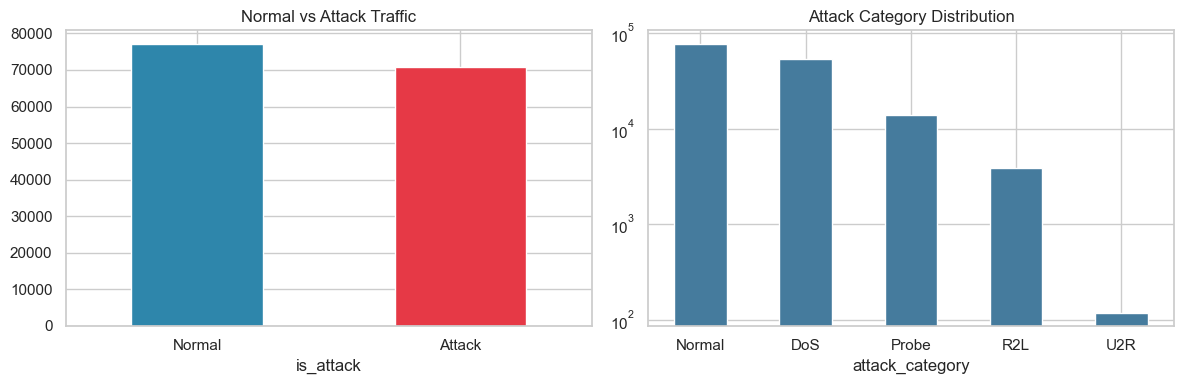

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
data["is_attack"].map({0: "Normal", 1: "Attack"}).value_counts().plot(kind="bar", color=["#2E86AB", "#E63946"])
plt.title("Normal vs Attack Traffic")
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
data["attack_category"].value_counts().plot(kind="bar", color="#457B9D")
plt.title("Attack Category Distribution")
plt.yscale("log")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**Isse kya pata chala:** Normal aur attack traffic overall lagbhag balanced hai, lekin attack types ke andar R2L aur U2R bahut kam hain. Yeh class imbalance problem hai, jise hum Step 11 mein fix karenge.

## Step 7: Feature engineering
Existing columns se naye behaviour-based features banate hain. Attacks mein aksar rates unusual hote hain (bahut fast connections, zyada failed logins, bytes ka imbalance).

In [7]:
duration = data["duration"].replace(0, 1)   # zero se divide na ho

data["total_bytes"] = data["src_bytes"] + data["dst_bytes"]
data["bytes_per_second"] = data["total_bytes"] / duration
data["src_bytes_per_second"] = data["src_bytes"] / duration
data["dst_bytes_per_second"] = data["dst_bytes"] / duration
data["src_dst_byte_ratio"] = (data["src_bytes"] + 1) / (data["dst_bytes"] + 1)
data["connections_per_second"] = data["count"] / duration
data["failed_login_rate"] = data["num_failed_logins"] / (data["count"] + 1)
data["error_rate_total"] = (data["serror_rate"] + data["rerror_rate"]) / 2
data["host_error_rate_total"] = (data["dst_host_serror_rate"] + data["dst_host_rerror_rate"]) / 2

print("Shape with new features:", data.shape)

Shape with new features: (147907, 52)


## Step 8: Categorical columns encode karo
Models ko numbers chahiye, isliye `protocol_type`, `service` aur `flag` ko one-hot encoding se convert karte hain. Labels ko features se alag rakhte hain.

In [8]:
y = data[["label", "attack_category", "is_attack"]]
X = data.drop(columns=["label", "attack_category", "is_attack"])

X = pd.get_dummies(X, columns=["protocol_type", "service", "flag"], dtype=int)

print("Features after encoding:", X.shape[1])

Features after encoding: 130


## Step 9: Train / Test split
Ab single dataset ko 80% train aur 20% test mein baantte hain. `stratify` lagane se har attack category ka ratio dono parts mein same rehta hai (rare U2R bhi dono mein aayega).

**Zaroori:** scaling aur SMOTE split ke **baad** karte hain, taaki test data ki information training mein leak na ho.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y["attack_category"])

X_train = X_train.copy()
X_test = X_test.copy()

print("Train:", X_train.shape)
print("Test :", X_test.shape)
print("\nTrain categories:")
print(y_train["attack_category"].value_counts())

Train: (118325, 130)
Test : (29582, 130)

Train categories:
attack_category
Normal    61573
DoS       42388
Probe     11163
R2L        3106
U2R          95
Name: count, dtype: int64


## Step 10: Features scale karo
1. Byte aur rate columns bahut skewed hain, isliye pehle log transform lagate hain.
2. Phir StandardScaler se saare numeric columns ko same scale par laate hain.

Scaler sirf **train** se seekhta hai (`fit_transform`) aur test par sirf apply hota hai (`transform`).

In [10]:
# 1) skewed columns par log transform
skewed = ["duration","src_bytes","dst_bytes","total_bytes","bytes_per_second",
          "src_bytes_per_second","dst_bytes_per_second","src_dst_byte_ratio","connections_per_second"]
X_train[skewed] = np.log1p(X_train[skewed])
X_test[skewed] = np.log1p(X_test[skewed])

# 2) standard scaling (sirf non 0/1 columns)
num_cols = [col for col in X_train.columns if X_train[col].nunique() > 2]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Scaled columns:", len(num_cols))
X_train.head()

Scaled columns: 41


,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
70271,-0.243046,1.210940,-0.896973,0,-0.085203,-0.01069,-0.093783,-0.059493,0,-0.010861,...,0,0,0,0,0,0,0,0,1,0
20158,-0.243046,-1.092564,-0.896973,0,-0.085203,-0.01069,-0.093783,-0.059493,0,-0.010861,...,0,0,0,0,1,0,0,0,0,0
140101,-0.243046,0.718092,0.556885,0,-0.085203,-0.01069,-0.093783,-0.059493,1,-0.010861,...,0,0,0,0,0,0,0,0,1,0
121857,-0.243046,0.818852,0.717709,0,-0.085203,-0.01069,-0.093783,-0.059493,1,-0.010861,...,0,0,0,0,0,0,0,0,1,0
3566,-0.243046,0.823014,1.289434,0,-0.085203,-0.01069,-0.093783,-0.059493,1,-0.010861,...,0,0,0,0,0,0,0,0,1,0


## Step 11: SMOTE se class imbalance handle karo
SMOTE rare classes (R2L aur U2R) ke liye synthetic samples banata hai. Ye **sirf training data** par lagta hai, test par kabhi nahi.

Hum rare classes ko sabse badi class ke lagbhag 10% tak badhate hain. Isse zyada karne par bahut kam real U2R rows se bahut zyada synthetic copies ban jaati.

In [11]:
counts = y_train["attack_category"].value_counts()
print("SMOTE se pehle:")
print(counts)

target = int(counts.max() * 0.10)
strategy = {}
for cls in counts.index:
    if counts[cls] < target:
        strategy[cls] = target

smote = SMOTE(sampling_strategy=strategy, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train["attack_category"])

print("\nSMOTE ke baad:")
print(y_train_smote.value_counts())

SMOTE se pehle:
attack_category
Normal    61573
DoS       42388
Probe     11163
R2L        3106
U2R          95
Name: count, dtype: int64

SMOTE ke baad:
attack_category
Normal    61573
DoS       42388
Probe     11163
R2L        6157
U2R        6157
Name: count, dtype: int64


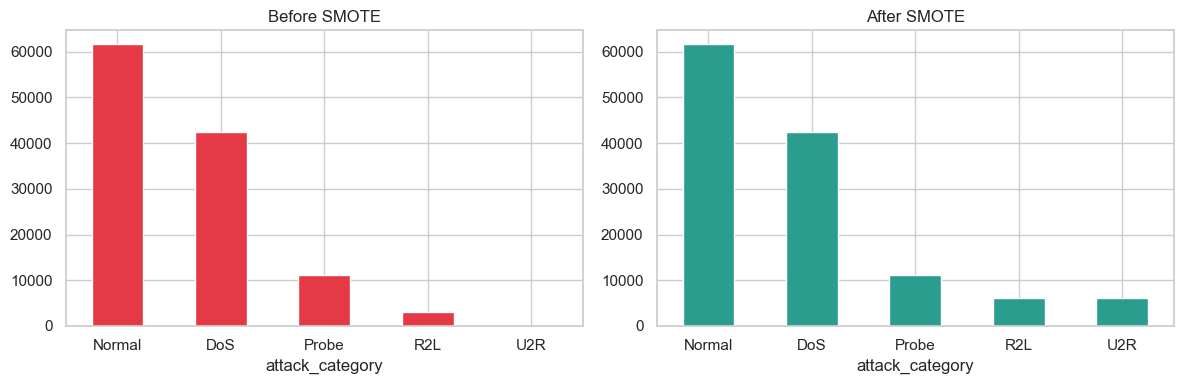

In [12]:
plt.figure(figsize=(12, 4))
order = ["Normal", "DoS", "Probe", "R2L", "U2R"]

plt.subplot(1, 2, 1)
counts.reindex(order).plot(kind="bar", color="#E63946")
plt.title("Before SMOTE")
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
y_train_smote.value_counts().reindex(order).plot(kind="bar", color="#2A9D8F")
plt.title("After SMOTE")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## Step 12: Processed data save karo

In [13]:
train_out = X_train.copy()
train_out["attack_category"] = y_train["attack_category"].values
train_out["is_attack"] = y_train["is_attack"].values

test_out = X_test.copy()
test_out["attack_category"] = y_test["attack_category"].values
test_out["is_attack"] = y_test["is_attack"].values

smote_out = X_train_smote.copy()
smote_out["attack_category"] = y_train_smote.values
smote_out["is_attack"] = (smote_out["attack_category"] != "Normal").astype(int)

train_out.to_csv("train_processed.csv", index=False)
test_out.to_csv("test_processed.csv", index=False)
smote_out.to_csv("train_processed_smote.csv", index=False)

print("Saved train_processed.csv      :", train_out.shape)
print("Saved test_processed.csv       :", test_out.shape)
print("Saved train_processed_smote.csv:", smote_out.shape)

Saved train_processed.csv      : (118325, 132)
Saved test_processed.csv       : (29582, 132)
Saved train_processed_smote.csv: (127438, 132)


## Done
Agla step: Logistic Regression (baseline), phir Random Forest, XGBoost, LightGBM, SVM aur Isolation Forest train karo. Training `train_processed.csv` ya `train_processed_smote.csv` par karo aur evaluation hamesha `test_processed.csv` par.

In [ ]:
d